# Classification using NN

### problem statement
+ predict if patient will face any hearing disease using age and physical score 

In [2]:
# Import required pkgs
import numpy as np
import pandas as pd
import torch
import seaborn as sns
import os
import matplotlib.pyplot as plt

In [3]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()          # Current working directory
DATASET = BASE_DIR / "hearing_test.csv"

In [4]:
df = pd.read_csv(DATASET)
print(DATASET)
df.head()

d:\Data Science AIML\Agentic_AI\code\DL\pytoch\4. classification\hearing_test.csv


,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


In [5]:
# get genral info about dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             5000 non-null   float64
 1   physical_score  5000 non-null   float64
 2   test_result     5000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 117.3 KB


In [6]:
# correlation analysis
df.corr()

,age,physical_score,test_result
age,1.000000,-0.782146,-0.683171
physical_score,-0.782146,1.000000,0.792716
test_result,-0.683171,0.792716,1.000000


In [7]:
# check if dataset is balaenced
df['test_result'].value_counts()

test_result
1    3000
0    2000
Name: count, dtype: int64

### data preparation


In [8]:
# split dataset
x = df.drop('test_result',axis=1)
y = df['test_result']

In [9]:
# split data into train and test
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

## DL


### check if GPU avilable 

In [10]:
# if device avilable shift to mps or cuds else cpu
# mps = metal performance shader
# compute unified device architecture is code word for Nvidia
device = ""
if torch.backends.mps.is_available():
    device='mps'
elif torch.cuda.is_available():
    device='cuda'
else:
    device='cpu'

print(f"found device is {device}")

found device is cuda


### convert dataset to tensor

In [11]:
# diemsion of x_train,x_test,,y_train,y_test must same
x_train = torch.FloatTensor(x_train.values).to(device)
x_test  = torch.FloatTensor(x_test.values).to(device)
y_train = torch.FloatTensor(y_train.values).to(device).view(-1,1)
y_test  = torch.FloatTensor(y_test.values).to(device).view(-1,1)

In [12]:
print(x_train.dtype)
print(x_test.dtype)
print(y_train.dtype)
print(y_test.dtype)

print(x_train.ndim)
print(x_test.ndim)
print(y_train.ndim)
print(y_test.ndim)


torch.float32
torch.float32
torch.float32
torch.float32
2
2
2
2


## Build model

| Problem                    | Hidden Layer Activation | Output Layer Activation                              | Loss Function                              |
| -------------------------- | ----------------------- | ---------------------------------------------------- | ------------------------------------------ |
| Regression                 | ReLU                    | **None**                                             | `nn.MSELoss()`                             |
| Binary Classification      | ReLU                    | **Sigmoid** *(or none if using `BCEWithLogitsLoss`)* | `nn.BCELoss()` or `nn.BCEWithLogitsLoss()` |
| Multiclass Classification  | ReLU                    | **None (no Softmax)**                                | `nn.CrossEntropyLoss()`                    |
| Multi-label Classification | ReLU                    | **Sigmoid**                                          | `nn.BCEWithLogitsLoss()`                   |


In [13]:
model = torch.nn.Sequential(

    # Inpput layer wiht 16 nurons
    torch.nn.Linear(in_features=2,out_features=16),
    # activation function
    torch.nn.ReLU(),

      # Hidden layer wiht 16 nurons
    torch.nn.Linear(in_features=16,out_features=8),
        # activation function
    torch.nn.ReLU(),

      # Inpput layer wiht 16 nurons
      # if we give out_feature = 2 then it will give probablity for (ex) spam also for ham
    torch.nn.Linear(in_features=8,out_features=1),
        # activation function = sigmoid on output as it is claassification. 
        # if its multiclass classification then we dont give any activation function at last layer, and loss function will be `CrossEntropyLoss()`
    torch.nn.Sigmoid()
).to(device)

    # move model to gpu
# model = model.to(device)

In [14]:
# model information
print(model)

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


### set hyper parameters

#### why BCELoss used here ? 
+ As we are using `Sigmoid()` function at output layer : it will gives us a `logit` values 
+ `BECLoss()/BCEWithLogitsLoss()` calculate loss using `logit` values 

| Classification Type       | X dtype   | y dtype   | y Shape | Loss Function                   |
| ------------------------- | --------- | --------- | ------- | ------------------------------- |
| Regression                | `float32` | `float32` | `(N,1)` | `MSELoss`                       |
| Binary Classification     | `float32` | `float32` | `(N,1)` | `BCELoss` / `BCEWithLogitsLoss` |
| Multiclass Classification | `float32` | `long`    | `(N,)`  | `CrossEntropyLoss`              |


In [15]:
# epochs
epochs= 10000

# learning rate 
lr = 0.01

# loss function
# since output layer has sigmoid as activation function the loss function must be Binary cross entropy
# it calclate logit values
loss_function = torch.nn.BCELoss()

# optimier
optimizer = torch.optim.Adam(model.parameters(),lr=lr)

## training loop

In [ ]:

# collcet all losses
losses = []

for epoch in range(epochs):

    # enable trainning mode
    model.train()

    # predict 
    # entire x_train loaded in memory and predicted by model 
    y_predict = model(x_train)

    #reset gradients
    optimizer.zero_grad()

    # calculte loss
    loss = loss_function(y_predict,y_train)

    # calculate loss gradients
    loss.backward()

    # adjust weigths
    optimizer.step()

    # append loss
    losses.append(loss.item())


    # every afyter 10 epochs print progress
    if epoch % 10 ==2 :
        print(f"epoch = {epoch}, loss = {loss}")



epoch = 2, loss = 0.36181581020355225
epoch = 12, loss = 0.23938027024269104
epoch = 22, loss = 0.23111197352409363
epoch = 32, loss = 0.2296241819858551
epoch = 42, loss = 0.2255353480577469
epoch = 52, loss = 0.22555167973041534
epoch = 62, loss = 0.22501446306705475
epoch = 72, loss = 0.22476233541965485
epoch = 82, loss = 0.22464311122894287
epoch = 92, loss = 0.2244863510131836
epoch = 102, loss = 0.22433653473854065
epoch = 112, loss = 0.22419501841068268
epoch = 122, loss = 0.224053755402565
epoch = 132, loss = 0.22390952706336975
epoch = 142, loss = 0.22376403212547302
epoch = 152, loss = 0.2236165851354599
epoch = 162, loss = 0.2234669327735901
epoch = 172, loss = 0.2233148217201233
epoch = 182, loss = 0.22316019237041473
epoch = 192, loss = 0.22300288081169128
epoch = 202, loss = 0.22284312546253204
epoch = 212, loss = 0.22268077731132507
epoch = 222, loss = 0.22251594066619873
epoch = 232, loss = 0.22234855592250824
epoch = 242, loss = 0.22217872738838196
epoch = 252, loss =

### visulaize training loss

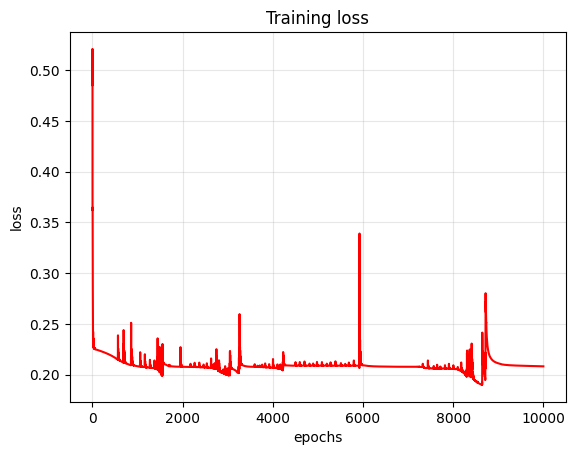

In [17]:
plt.plot(np.arange(epochs),losses, color='red')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.title('Training loss')
plt.grid(alpha=0.3)

# Evaluate model

### Trainning accuracy

In [18]:

from sklearn.metrics import accuracy_score,classification_report
# trainning
# enable evaluation mode
model.eval()

# disable training weights and training parameters
with torch.no_grad():
    # predict x-test
    y_hat1 = model(x_train)

    # predict classes
    prediction_classes = (y_hat1 >0.5).float()

    # calculate accurcy
    # sinces accuracy not support tensor so convert to cpu first then calculate accuracy
    # accuracy = accuracy_score(y_test.to('cpu').numpy(),y_hat.to('cpu').numpy())
    accuracy = accuracy_score(
    y_train.cpu().numpy(),
    prediction_classes.cpu().numpy()
)

print(f"Accuracy : {accuracy*100:.2f}")    
print(classification_report(
    y_train.cpu().numpy(),
    prediction_classes.cpu().numpy()))


Accuracy : 92.00
              precision    recall  f1-score   support

         0.0       0.93      0.87      0.90      1616
         1.0       0.91      0.96      0.93      2384

    accuracy                           0.92      4000
   macro avg       0.92      0.91      0.92      4000
weighted avg       0.92      0.92      0.92      4000



#### testing accuracy

In [19]:
# enable evaluation mode
model.eval()

# disable training weights and training parameters
with torch.no_grad():
    # predict x-test
    y_hat = model(x_test)

    # predict classes
    prediction_classes = (y_hat >0.5).float()


    # calculate accurcy by mnaullay
    # this doest not need to shift on cpu to calculate accuray : prefeereed over sklearn accuracy 
    accuracy = (prediction_classes == y_test).float().mean()

print(f"Accuracy : {accuracy*100:.2f}")    



Accuracy : 90.10


In [20]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
# enable evaluation mode
model.eval()

# disable training weights and training parameters
with torch.no_grad():
    # predict x-test
    y_hat = model(x_test)

    # predict classes
    prediction_classes = (y_hat >0.5).float()

    # calculate accurcy
    # sinces accuracy not support tensor so convert to cpu first then calculate accuracy
    # accuracy = accuracy_score(y_test.to('cpu').numpy(),y_hat.to('cpu').numpy())
    accuracy = accuracy_score(
    y_test.cpu().numpy(),
    prediction_classes.cpu().numpy()
)

print(f"Accuracy : {accuracy*100:.2f}")    
print(classification_report(
    y_test.cpu().numpy(),
    prediction_classes.cpu().numpy()))



Accuracy : 90.10
              precision    recall  f1-score   support

         0.0       0.89      0.85      0.87       384
         1.0       0.91      0.93      0.92       616

    accuracy                           0.90      1000
   macro avg       0.90      0.89      0.89      1000
weighted avg       0.90      0.90      0.90      1000



In [21]:
confusion_matrix(y_test.cpu(),prediction_classes.cpu())

array([[326,  58],
       [ 41, 575]])